In [1]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io
import elli

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Permittivity_study\fit_interband_permittivity')
from fit_interband_func import *
import fit_interband_func
importlib.reload(fit_interband_func)
from fit_interband_func  import *



os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\Permittivity changes estimation')
from Permittivity_change_func import *
import Permittivity_change_func
importlib.reload(Permittivity_change_func)
from Permittivity_change_func  import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

In [2]:
Au_band_info = {}

## From the mathematica code used for Stoll 2014
## Define all parameters
Au_info = {}

Au_info['Rosei'] = {}
# Masses in electron mass unit    
Au_info['Rosei']['m_d_perp_L'] = 0.874
Au_info['Rosei']['m_d_par_L'] = 0.813
Au_info['Rosei']['m_p_perp_L'] = 0.223
Au_info['Rosei']['m_p_par_L'] = 0.254
Au_info['Rosei']['m_s_perp_L'] = 0.49
Au_info['Rosei']['m_s_par_L'] = 0.57

Au_info['Rosei']['m_d_perp_X'] = 0.704
Au_info['Rosei']['m_d_par_X'] = 1.03
Au_info['Rosei']['m_p_perp_X'] = 0.242
Au_info['Rosei']['m_p_par_X'] = 0.121


#Optical gaps in eV from Christensens (based on mathematica alpha code)
Au_info['Rosei']['wf_L'] = 1368e-3 #in eV
Au_info['Rosei']['wo_L'] = 798e-3 #in eV
Au_info['Rosei']['wg_L'] = 3264e-3 #in eV


Au_info['Rosei']['wg_X'] = 573e-3 #in eV
Au_info['Rosei']['wf_X'] = 1570e-3 #in eV

# Fermi Energy from Ascroft solid state physics
Au_info['Rosei']['Ef'] = 5530e-3 #in eV
#Drude parameters from JaC
Au_info['Rosei']['wp'] = 9.01 #in eV
Au_info['Rosei']['gamma0'] = 0.067 #in eV

# Read from Tatjana PhD
Au_info['Rosei']['wp'] = 8.984361811594203 #in eV
Au_info['Rosei']['gamma0'] = 0.067 #in eV



norm_factor = np.sqrt(8e-33)#temporaire parce que je sais pas encore bien normaliser avec les unités
Au_info['Rosei']['Pdp_L'] = 17.8*norm_factor #in 10^11 m_e^2  m^2/s^2
Au_info['Rosei']['Pps_L'] = 4.85*norm_factor #in 10^11 m_e^2  m^2/s^2
Au_info['Rosei']['Pdp_X'] = 1.7*norm_factor



Au_info['Stoll 2014 fitted'] = {}
for key in Au_info['Rosei'] :
    Au_info['Stoll 2014 fitted'][key] = Au_info['Rosei'][key]

#Update the value that changed from Rosei

Au_info['Stoll 2014 fitted']['wf_L'] = 718e-3 #in eV
Au_info['Stoll 2014 fitted']['wo_L'] = 1560e-3 #in eV
Au_info['Stoll 2014 fitted']['wg_L'] = 2600e-3 #in eV

Au_info['Stoll 2014 fitted']['wf_X'] = 1770e-3 #in eV
Au_info['Stoll 2014 fitted']['wg_X'] = 1476e-3 #in eV


norm_factor = np.sqrt(8e-33)#temporaire parce que je sais pas encore bien normaliser avec les unités
Au_info['Stoll 2014 fitted']['Pdp_L'] = np.sqrt(17.8)*norm_factor #in 10^11 m_e^2  m^2/s^2
Au_info['Stoll 2014 fitted']['Pps_L'] = np.sqrt(4.85)*norm_factor #in 10^11 m_e^2  m^2/s^2
Au_info['Stoll 2014 fitted']['Pdp_X'] = np.sqrt(5.7)*norm_factor


Source = 'Rosei' #As it is named in the mathematica code
Source = 'Stoll 2014 fitted'



Au_band_info = Au_info[Source]

Ef = Au_info[Source]['Ef'] #in eV
Emin = Ef - 5

m_p_perp_L = Au_info[Source]['m_p_perp_L']
m_p_par_L = Au_info[Source]['m_p_par_L']
m_s_perp_L = Au_info[Source]['m_s_perp_L']
m_s_par_L = Au_info[Source]['m_s_par_L']

#gaps in eV
wf_L = Au_info[Source]['wf_L'] 
wg_L = Au_info[Source]['wg_L']

wf_X = Au_info[Source]['wf_X'] 
wg_X = Au_info[Source]['wg_X']

dir_to_save = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Interband sensitivity model\Interbande_fits'

dir_to_save += r'\Stoll_2014'

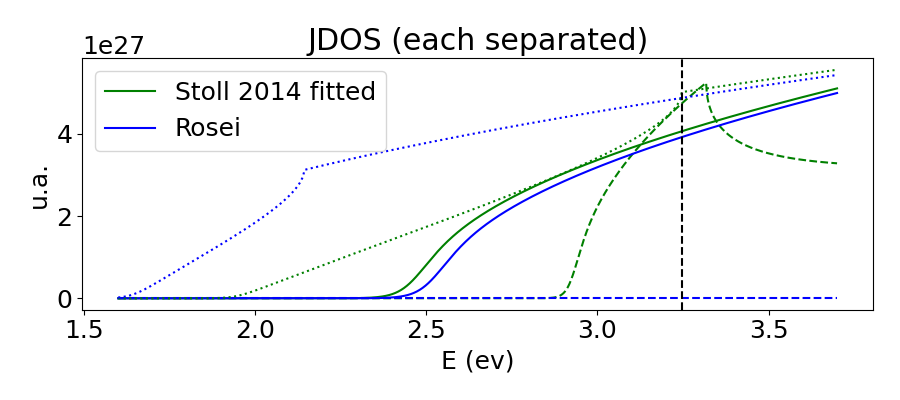

In [3]:
E_low = 1.6
E_high = 3.7
E = np.linspace(E_low, E_high, 1000) #in eV
prefactor = 8*np.pi**2 * sc.constants.hbar**2 / (sc.constants.epsilon_0*sc.constants.m_e**2)



fig, ax =plt.subplots(figsize=(9,4))


ax.plot(E, Jps_L_Au(E, **Au_info['Stoll 2014 fitted']), color='green', linestyle='--')
ax.plot(E, Jdp_L_Au(E, **Au_info['Stoll 2014 fitted']), color='green', label = 'Stoll 2014 fitted')
ax.plot(E, Jps_L_Au(E, **Au_info['Rosei']), color='blue', linestyle='--')
ax.plot(E, Jdp_L_Au(E, **Au_info['Rosei']), color='blue', label = 'Rosei')

ax.plot(E, Jdp_X_Au(E, **Au_info['Stoll 2014 fitted']), color='green', linestyle='dotted')
ax.plot(E, Jdp_X_Au(E, **Au_info['Rosei']), color='blue', linestyle='dotted')

ax.axvline(wf_X+wg_X, linestyle='--', color='black')


ax.set_xlabel('E (ev)')
ax.set_ylabel('u.a.')
ax.set_title('JDOS (each separated)')

ax.legend()
plt.tight_layout()

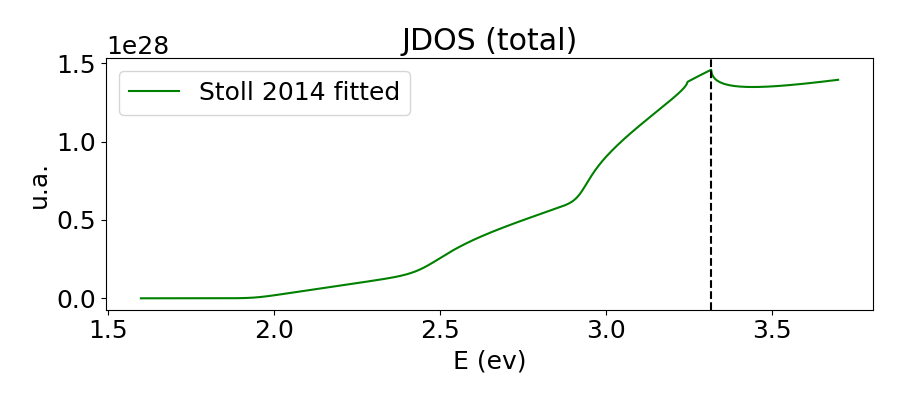

In [4]:
fig, ax =plt.subplots(figsize=(9,4))

ax.plot(E, Jps_L_Au(E, **Au_info['Stoll 2014 fitted']) + Jdp_L_Au(E, **Au_info['Stoll 2014 fitted']) + Jdp_X_Au(E, **Au_info['Stoll 2014 fitted']), color='green', label = 'Stoll 2014 fitted')
ax.axvline(wf_L+wg_L, linestyle='--', color='black')


ax.set_xlabel('E (ev)')
ax.set_ylabel('u.a.')
ax.set_title('JDOS (total)')

ax.legend()
plt.tight_layout()

## Fit experimental data

### Get experimental data

In [5]:
# Get the Jhonson and Christy permittivity.
dir_root = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\Data_refractive_index'
fname = 'Au - jhonson Christy.csv'
data = get_permittivity_tabulated_data(dir_root, fname)


### Remove the Drude part

In [6]:
#Gold values from Romain PhD manuscript
wp = Au_band_info['wp']  
gamma0 = Au_band_info['gamma0'] 


eps2_ib = data['eps_2'] - eps_2_drude(data['eV'], gamma=gamma0, w_p=wp)
eps2_ib_interp = sc.interpolate.interp1d(data['eV'], eps2_ib, fill_value=0, kind='quadratic')

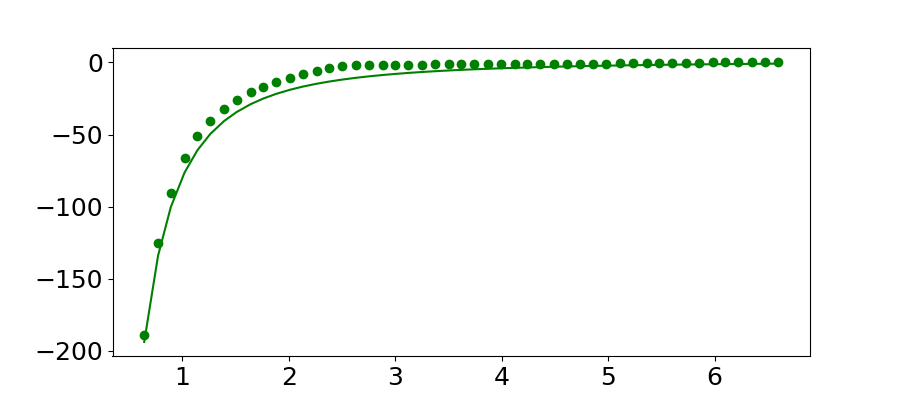

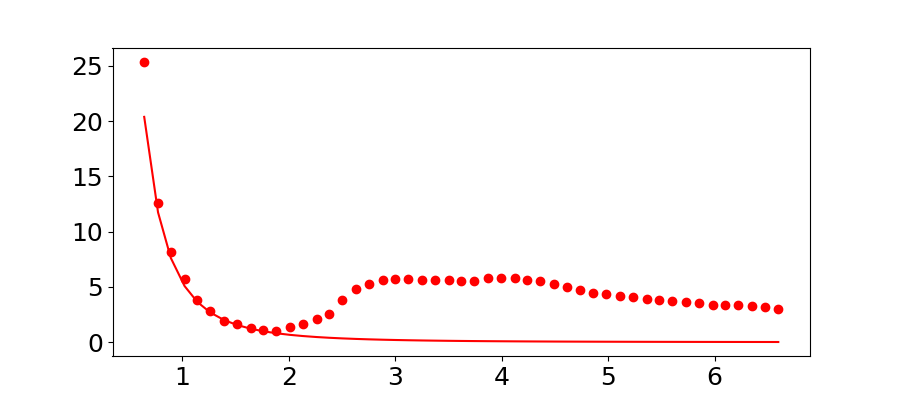

In [7]:
fig, ax =plt.subplots(figsize=(9,4))

ax.plot(data['eV'], eps_1_drude(data['eV'], gamma0, wp), color='green', label = 'Stoll 2014 Drude')
ax.scatter(data['eV'], data['eps_1'] , color='green', label = 'Jhonson and Christy')

fig, ax =plt.subplots(figsize=(9,4))

ax.plot(data['eV'], eps_2_drude(data['eV'], gamma0, wp), color='red', label = 'Stoll 2014 fitted')
ax.scatter(data['eV'], data['eps_2'] , color='red', label = 'Jhonson and Christy')

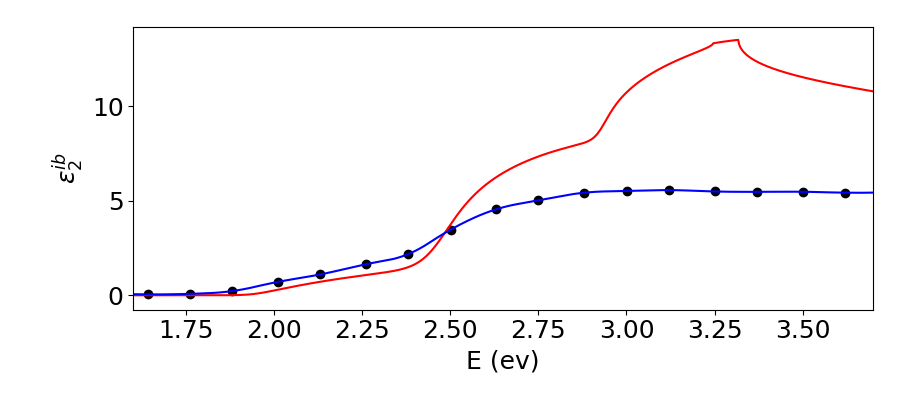

In [8]:
fig, ax =plt.subplots(figsize=(9,4))


ax.plot(E, eps2_from_interband_Au(E, **Au_info['Stoll 2014 fitted']), color='red', label = 'Fit Stoll 2014')
ax.plot(E, eps2_ib_interp(E), color='blue', )
ax.scatter(data['eV'], eps2_ib , color='black', )
ax.set_xlim((E_low, E_high))
ax.set_xlabel('E (ev)')
ax.set_ylabel(r'$\varepsilon_2^{ib}$')
plt.tight_layout()

In [9]:
free_param_list = ['wg_L', 'wo_L', 'Pdp_L', 'Pps_L', 'wf_X', 'Pdp_X']
free_param_list = ['wg_L', 'wo_L', 'Pdp_L', 'Pps_L', 'wf_X', 'wg_X', 'Pdp_X']


#idx_data = np.where((data['eV']>=3.5 * data['eV']<=4.6))
Xdata = data['eV'][(data['eV']>=E_low) & (data['eV']<=E_high)]
Ydata = eps2_ib_interp(Xdata)

Au_info['my fit'], fit_res_err = make_Au_interband_fit(Au_info['Rosei'], free_param_list, Xdata, Ydata)
Au_info['my fit'], fit_res_err = make_Au_interband_fit(Au_info['Stoll 2014 fitted'], free_param_list, Xdata, Ydata)

------------Initial parameters ------------------
key : wg_L / value : 3.264
key : wo_L / value : 0.798
key : Pdp_L / value : 1.5920803999798503e-15
key : Pps_L / value : 4.3379718763495914e-16
key : wf_X / value : 1.57
key : wg_X / value : 0.573
key : Pdp_X / value : 1.520526224699857e-16
------------------------------------------------
------------Fitted parameters ------------------
key : wg_L / value : 3.264 / error : inf
key : wo_L / value : 0.798 / error : inf
key : Pdp_L / value : 1.5920803999798503e-15 / error : inf
key : Pps_L / value : 4.3379718763495914e-16 / error : inf
key : wf_X / value : 1.57 / error : inf
key : wg_X / value : 0.573 / error : inf
key : Pdp_X / value : 1.520526224699857e-16 / error : inf
----------------------------------------------
------------Initial parameters ------------------
key : wg_L / value : 2.6
key : wo_L / value : 1.56
key : Pdp_L / value : 3.773592452822641e-16
key : Pps_L / value : 1.969771560359221e-16
key : wf_X / value : 1.77
key : wg_X

C:\Users\nberr\ENS_Lyon\Thèse\Code\Permittivity_study\fit_interband_permittivity\fit_interband_func.py:368: RuntimeWarning:

invalid value encountered in sqrt

C:\Users\nberr\ENS_Lyon\Thèse\Code\Permittivity_study\fit_interband_permittivity\fit_interband_func.py:516: OptimizeWarning:

Covariance of the parameters could not be estimated



------------Fitted parameters ------------------
key : wg_L / value : 2.9024381876425775 / error : 0.03568258519037826
key : wo_L / value : 1.5095325899252392 / error : 0.011143732192787059
key : Pdp_L / value : 2.4320594885991653e-16 / error : 6.563831649079665e-18
key : Pps_L / value : -6.80999091783645e-17 / error : 6.383442447298119e-18
key : wf_X / value : 1.7342009952058457 / error : 0.022043008565031268
key : wg_X / value : 1.0743057985870827 / error : 0.04039663609996822
key : Pdp_X / value : 2.1367275722985266e-16 / error : 6.806804682193182e-18
----------------------------------------------


In [10]:
for key in free_param_list :
    print((key, Au_info['Stoll 2014 fitted'][key], Au_info['my fit'][key]))

('wg_L', 2.6, np.float64(2.9024381876425775))
('wo_L', 1.56, np.float64(1.5095325899252392))
('Pdp_L', np.float64(3.773592452822641e-16), np.float64(2.4320594885991653e-16))
('Pps_L', np.float64(1.969771560359221e-16), np.float64(-6.80999091783645e-17))
('wf_X', 1.77, np.float64(1.7342009952058457))
('wg_X', 1.476, np.float64(1.0743057985870827))
('Pdp_X', np.float64(2.1354156504062622e-16), np.float64(2.1367275722985266e-16))


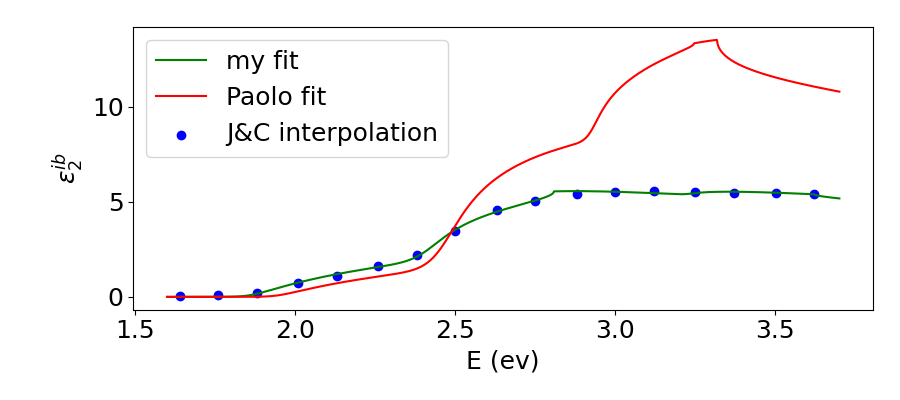

In [11]:
fig, ax =plt.subplots(figsize=(9,4))
ax.plot(E, eps2_from_interband_Au(E, **Au_info['my fit']), color='green', label = 'my fit')
ax.plot(E, eps2_from_interband_Au(E, **Au_info['Stoll 2014 fitted']) , color='red', label='Paolo fit')
ax.scatter(Xdata, Ydata, color='blue', label = 'J&C interpolation')
ax.legend()
ax.set_xlabel('E (ev)')
ax.set_ylabel(r'$\varepsilon_2^{ib}$')
plt.tight_layout()

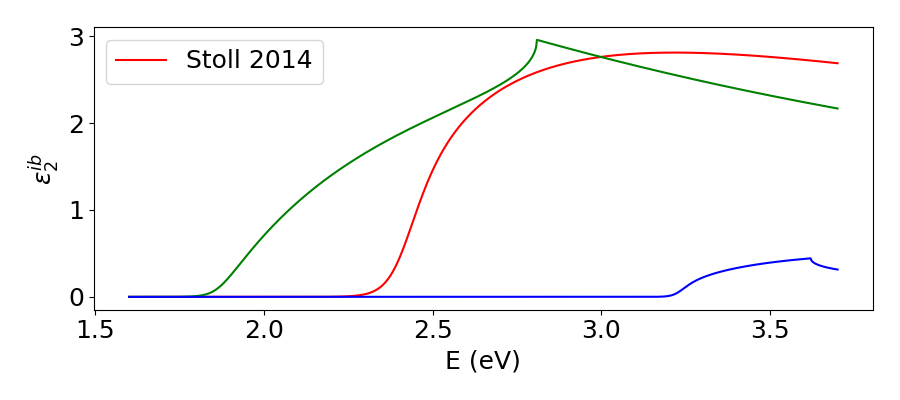

In [12]:
fig, ax =plt.subplots(figsize=(9,4))

ax.plot(E, eps2_Jdp_L_interband_Au(E, **Au_info['my fit']), color='red', label = 'Stoll 2014')
ax.plot(E, eps2_Jdp_X_interband_Au(E, **Au_info['my fit']), color='green')
ax.plot(E, eps2_Jps_L_interband_Au(E, **Au_info['my fit']), color='blue')


#ax.plot(E, eps2_from_interband_Au(E, **Au_info['Stoll 2014 fitted']) , color='red', label='Paolo fit')
#ax.scatter(Xdata, Ydata, color='blue', label = 'J&C interpolation')
ax.legend()

ax.set_xlabel('E (eV)')
ax.set_ylabel(r'$\varepsilon_2^{ib}$ ')
plt.tight_layout()

os.chdir(dir_to_save)
plt.savefig('Each band data wit stoll fit.png')
plt.savefig('Each band data wit stoll fit.pdf')

## Save fitted parameters

In [13]:
save_data = 0
if save_data :

    dir_to_save = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Interband sensitivity model\Interbande_fits'

    dir_to_save += r'\Stoll_2014'

    save_eps2_fitted(dir_to_save, fname = 'eps_2_fit.csv', Fit_dic_info=Au_info['Stoll 2014 fitted'])
    save_fit_parameters(dir_to_save, fname = 'fit_parameters.csv', Fit_dic_info=Au_info['Stoll 2014 fitted'])